In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Read CSV file

In [3]:
df = pd.read_csv("Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# 1. Data Cleaning

In [4]:
print("Number of Rows: ", df.shape[0])
print("Number of Column: ", df.shape[1])
print("\nColumn names: ")
print(df.columns.tolist())

Number of Rows:  7043
Number of Column:  21

Column names: 
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


### 1.1 Datatypes

In [5]:
print("Data Types:")
print(df.dtypes)

Data Types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


### 1.2 Checking Missing value

In [6]:
print("Missing Values: ")
print(df.isnull().sum())

Missing Values: 
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


### 1.3 Total Charges datatype

In [7]:
print(df["TotalCharges"].dtypes)

str


### 1.4 Converting datatype

In [8]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

### 1.5 Checking Missing values 

In [9]:
print("Missing valuess after conversion: ")
print(df.isnull().sum())

Missing valuess after conversion: 
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


### 1.6 Removing Missing Rows

In [10]:
df = df.dropna(subset=["TotalCharges"])

In [11]:
print("Dataset shape after cleaning: ",df.shape)
print("Total Missing values: ",df.isnull().sum())

Dataset shape after cleaning:  (7032, 21)
Total Missing values:  customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


### 1.7 Duplicate Customers

In [12]:
print("Duplicate customer IDs: ", df["customerID"].duplicated().sum())

Duplicate customer IDs:  0


# 2. Calculate Churn count

### 2.1 Total Churn

In [13]:
churn_count = df["Churn"].value_counts()
print(churn_count)

Churn
No     5163
Yes    1869
Name: count, dtype: int64


### 2.2 Percentage

In [14]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100
print(churn_percentage)

Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


### 2.3 Customer Churn distribution chart 

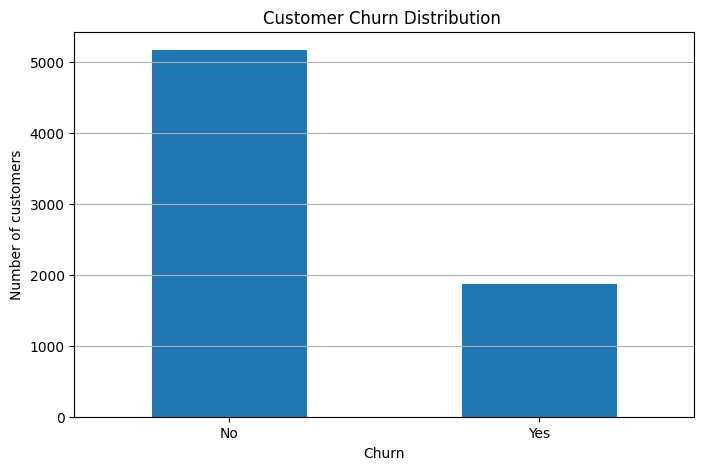

In [15]:
churn_count.plot(kind="bar", figsize=(8,5))
plt.title("Customer Churn Distribution ")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

### 2.4 Churn by contract type

In [16]:
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
print(contract_churn)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.722826  11.277174
Two year        97.151335   2.848665


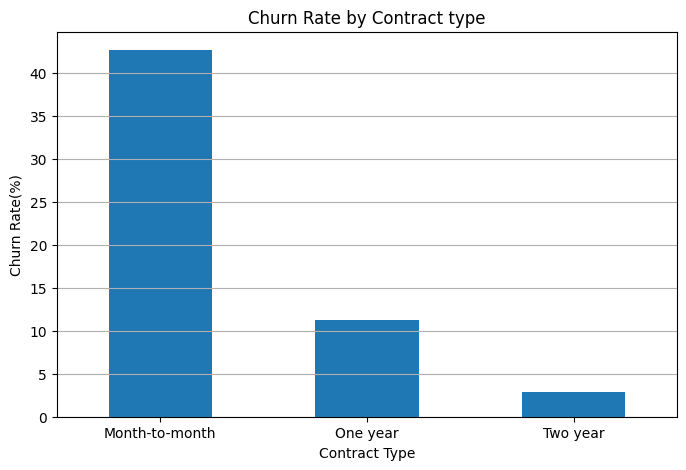

In [17]:
contract_churn["Yes"].plot(kind="bar", figsize=(8,5))
plt.title("Churn Rate by Contract type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate(%)")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

### 2.5 Churn by tenure

In [18]:
# Create tenure groups
df["TenureGroup"] = pd.cut(df["tenure"], 
                           bins=[0, 12, 24, 48, 72], 
                           labels=["0-12 Months", "12-24 Months", "24-48 Months", "48-72 Months"])

In [19]:
# Calculate churn rate
tenure_churn = pd.crosstab(df["TenureGroup"], df["Churn"], normalize = "index") * 100
print(tenure_churn)

Churn                No        Yes
TenureGroup                       
0-12 Months   52.321839  47.678161
12-24 Months  71.289062  28.710938
24-48 Months  79.611041  20.388959
48-72 Months  90.486824   9.513176


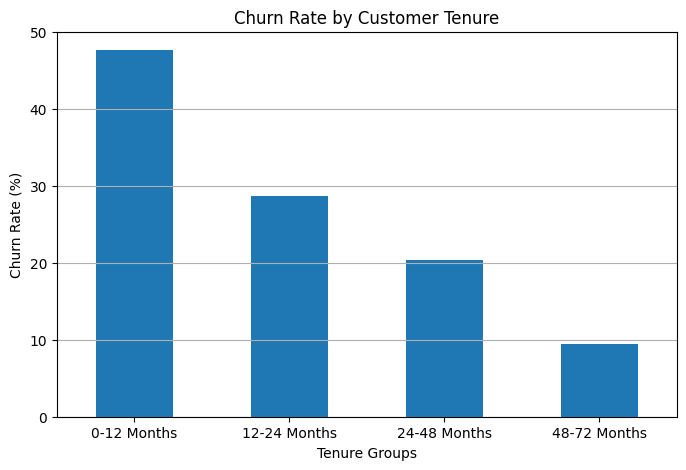

In [20]:
# Chart
tenure_churn["Yes"].plot(kind="bar", figsize=(8,5))
plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure Groups")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

### 2.6 Churn by Monthly Charges

In [21]:
#Create Group
df["MonthlyChargesGroups"] = pd.cut(df["MonthlyCharges"],
                                    bins=[0, 30, 60, 90, 120],
                                    labels=["0-30","30-60","60-90","90-120"])

In [22]:
# Calculate churn value
charge_churn = pd.crosstab(df["MonthlyChargesGroups"], df["Churn"], normalize="index") * 100
print(charge_churn)

Churn                        No        Yes
MonthlyChargesGroups                      
0-30                  90.163934   9.836066
30-60                 74.030087  25.969913
60-90                 66.051196  33.948804
90-120                67.222542  32.777458


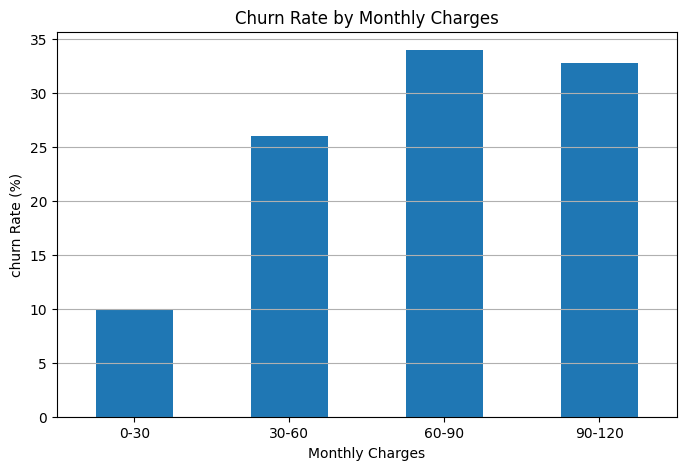

In [23]:
# Chart
charge_churn["Yes"].plot(kind="bar", figsize=(8,5))
plt.title("Churn Rate by Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("churn Rate (%)")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

### 2.7 Churn by Internet Services

In [24]:
internet_churn = pd.crosstab(df["InternetService"], df["Churn"], normalize="index") * 100
print(internet_churn)

Churn                   No        Yes
InternetService                      
DSL              81.001656  18.998344
Fiber optic      58.107235  41.892765
No               92.565789   7.434211


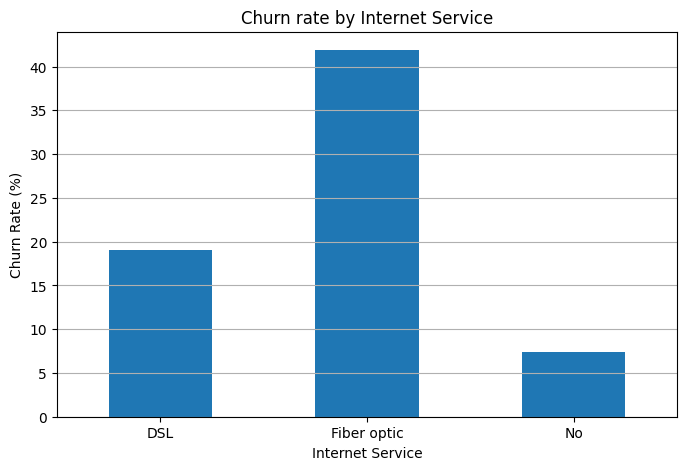

In [25]:
# chart
internet_churn["Yes"].plot(kind="bar", figsize=(8,5))
plt.title("Churn rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

### 2.8 Churn Rate by Payment Method

In [26]:
payment_churn = pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index") * 100
print(payment_churn)

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.268482  16.731518
Credit card (automatic)    84.746877  15.253123
Electronic check           54.714588  45.285412
Mailed check               80.798005  19.201995


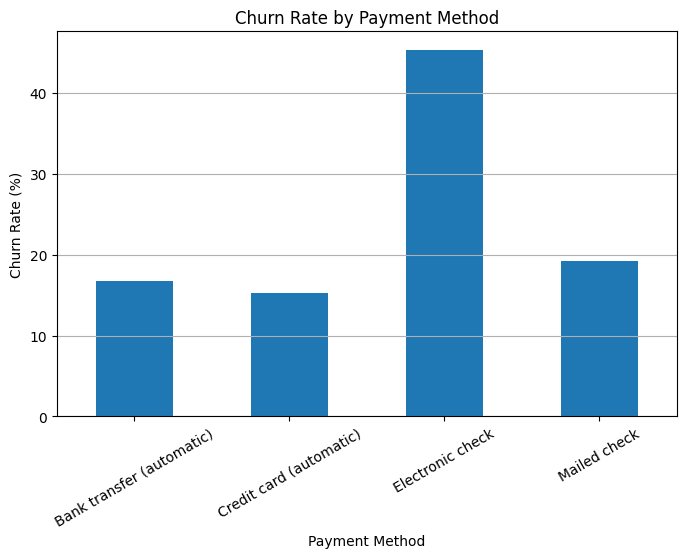

In [27]:
# Chart
payment_churn["Yes"].plot(kind="bar", figsize=(8,5))
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)
plt.grid(axis="y")
plt.show()

### 2.9 Churn rate by tech support

In [28]:
tech_churn = pd.crosstab(df["TechSupport"], df["Churn"], normalize="index") * 100
print(tech_churn)

Churn                       No        Yes
TechSupport                              
No                   58.352535  41.647465
No internet service  92.565789   7.434211
Yes                  84.803922  15.196078


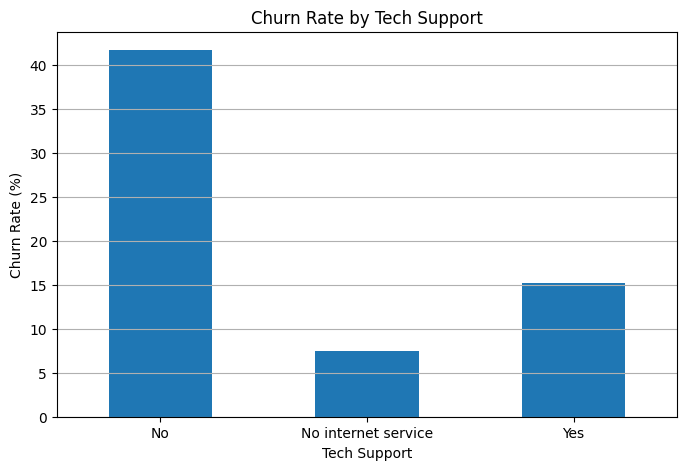

In [29]:
# Chart
tech_churn["Yes"].plot(kind="bar", figsize=(8,5))
plt.title("Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

# 3 Exact Churn Rate

In [30]:

print("Overall Churn Rate: ")
print(df["Churn"].value_counts(normalize=True) * 100)

print("\nChurn Rate by Contract: ")
print(contract_churn["Yes"])


print("\nChurn Rate by Tenure: ")
print(tenure_churn["Yes"])

print("\nChurn Rate by Monthly Charges: ")
print(charge_churn["Yes"])


print("\nChurn Rate by Internet Service: ")
print(internet_churn["Yes"])

print("\nChurn Rate by Payment Method: ")
print(payment_churn["Yes"])

print("\nChurn Rate by Tech Support: ")
print(tech_churn["Yes"])



Overall Churn Rate: 
Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64

Churn Rate by Contract: 
Contract
Month-to-month    42.709677
One year          11.277174
Two year           2.848665
Name: Yes, dtype: float64

Churn Rate by Tenure: 
TenureGroup
0-12 Months     47.678161
12-24 Months    28.710938
24-48 Months    20.388959
48-72 Months     9.513176
Name: Yes, dtype: float64

Churn Rate by Monthly Charges: 
MonthlyChargesGroups
0-30       9.836066
30-60     25.969913
60-90     33.948804
90-120    32.777458
Name: Yes, dtype: float64

Churn Rate by Internet Service: 
InternetService
DSL            18.998344
Fiber optic    41.892765
No              7.434211
Name: Yes, dtype: float64

Churn Rate by Payment Method: 
PaymentMethod
Bank transfer (automatic)    16.731518
Credit card (automatic)      15.253123
Electronic check             45.285412
Mailed check                 19.201995
Name: Yes, dtype: float64

Churn Rate by Tech Support: 
TechSupport
No            

# 4. Summary

In [31]:
summary = pd.DataFrame({
    "Analysis": [
        "Overall churn",
        "Month-to-Month Churn Contract",
        "One Year contract",
        "Two Year Contract",
        "Tech Support - No",
        "Tech Support - Yes"
    ],
    "Churn Rate (%)": [
        df["Churn"].value_counts(normalize=True)["Yes"] * 100,
        contract_churn.loc["Month-to-month","Yes"],
        contract_churn.loc["One year","Yes"],
        contract_churn.loc["Two year","Yes"],
        tech_churn.loc["No","Yes"],
        tech_churn.loc["Yes","Yes"],
    ]
})
summary

,Analysis,Churn Rate (%)
0,Overall churn,26.578498
1,Month-to-Month Churn Contract,42.709677
2,One Year contract,11.277174
3,Two Year Contract,2.848665
4,Tech Support - No,41.647465
5,Tech Support - Yes,15.196078


# 5. High Risk Customer

In [40]:
# Select high risk customer
high_risk = df[
    (df["Contract"].str.strip() == "Month-to-month") & 
    (df["tenure"] <= 12) &
    (df["Churn"].str.strip() == "No")
]
# Display high risk custome count
print("High Risk Customer count: ", len(high_risk))

# Details
print("High Risk Customer details: ")
print(high_risk[["customerID", "tenure", "Contract", "MonthlyCharges"]].head(10))


High Risk Customer count:  970
High Risk Customer details: 
    customerID  tenure        Contract  MonthlyCharges
0   7590-VHVEG       1  Month-to-month           29.85
7   6713-OKOMC      10  Month-to-month           29.75
31  4929-XIHVW       2  Month-to-month           95.50
33  7310-EGVHZ       1  Month-to-month           20.20
34  3413-BMNZE       1  Month-to-month           45.25
46  5948-UJZLF       2  Month-to-month           49.25
65  5122-CYFXA       3  Month-to-month           75.30
69  7410-OIEDU      10  Month-to-month           79.85
70  2273-QCKXA       1  Month-to-month           49.05
74  5630-AHZIL       3  Month-to-month           64.50
